# Model-based and sequential feature selection: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/feature_selection/plot_select_from_model_diabetes.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/feature_selection/plot_select_from_model_diabetes.html)).

**Scenario:** on the bundled diabetes data, a ridge model's absolute coefficients are the feature
importances. `SelectFromModel` keeps features above a threshold just over the third-largest importance,
and `SequentialFeatureSelector` picks two features greedily, forward and backward, with 5-fold CV R².
The notebook adds `RFE` and `RFECV` with the same model, since they consume the same importances.

**Adaptations:**
- Moxie has no `RidgeCV`. The example's `RidgeCV(alphas=np.logspace(-6, 6, num=5))` selects
  `alpha_` by efficient leave-one-out on the full data; Moxie uses `Ridge(alpha=alpha_)` with that value.
  For `SelectFromModel` this is identical (RidgeCV refits on the same data and selects the same alpha).
  For `SequentialFeatureSelector`, sklearn clones RidgeCV in every fold, so alpha could change per fold;
  the Python reference therefore also runs SFS with `Ridge(alpha=alpha_)` and both supports are compared.
- Moxie wraps the model in the typed `RidgeImportance` adapter (SelectFromModel/RFE/RFECV) and
  `DenseSupervisedCV[Ridge]` (SequentialFeatureSelector).
- The example's second part (breast cancer, `LogisticRegression`, `scoring="roc_auc"`, `n_jobs=2`,
  `tol` in a pipeline) is recorded as a `GAP`: Moxie has no `LogisticRegression` and no string scorer lookup.
- Timing prints are kept on the Python side only.

**Determinism:** deterministic (closed-form ridge solutions, unshuffled `KFold`).

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("feature_selection/plot_select_from_model_diabetes")

## 1. scikit-learn (Python reference)

The official example code (DESCR print and the breast-cancer part omitted, figure shrunk).

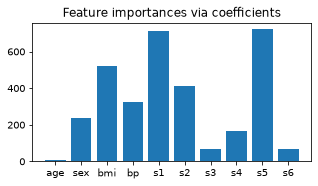

Features selected by SelectFromModel: ['s1' 's5']
Done in 0.001s


Features selected by forward sequential selection: ['bmi' 's5']
Done in 0.121s
Features selected by backward sequential selection: ['bmi' 's5']
Done in 0.345s


In [2]:
from sklearn.datasets import load_diabetes

diabetes = load_diabetes()
X, y = diabetes.data, diabetes.target

import matplotlib.pyplot as plt
import numpy as np

from sklearn.linear_model import RidgeCV

ridge = RidgeCV(alphas=np.logspace(-6, 6, num=5)).fit(X, y)
importance = np.abs(ridge.coef_)
feature_names = np.array(diabetes.feature_names)
plt.figure(figsize=(5, 2.5), dpi=72)
plt.bar(height=importance, x=feature_names)
plt.title("Feature importances via coefficients")
plt.show()

from time import time

from sklearn.feature_selection import SelectFromModel

threshold = np.sort(importance)[-3] + 0.01

tic = time()
sfm = SelectFromModel(ridge, threshold=threshold).fit(X, y)
toc = time()
print(f"Features selected by SelectFromModel: {feature_names[sfm.get_support()]}")
print(f"Done in {toc - tic:.3f}s")

from sklearn.feature_selection import SequentialFeatureSelector

tic_fwd = time()
sfs_forward = SequentialFeatureSelector(ridge, n_features_to_select=2, direction="forward").fit(X, y)
toc_fwd = time()

tic_bwd = time()
sfs_backward = SequentialFeatureSelector(ridge, n_features_to_select=2, direction="backward").fit(X, y)
toc_bwd = time()

print("Features selected by forward sequential selection: "
      f"{feature_names[sfs_forward.get_support()]}")
print(f"Done in {toc_fwd - tic_fwd:.3f}s")
print("Features selected by backward sequential selection: "
      f"{feature_names[sfs_backward.get_support()]}")
print(f"Done in {toc_bwd - tic_bwd:.3f}s")

Reference values with `Ridge(alpha=ridge.alpha_)`, and `RFE`/`RFECV` with the same model.

In [3]:
from sklearn.linear_model import Ridge
from sklearn.feature_selection import RFE, RFECV

alpha = ridge.alpha_
print("RidgeCV alpha_:", alpha)
fixed = Ridge(alpha=alpha)
ref = {}
ref["coef"] = Ridge(alpha=alpha).fit(X, y).coef_
ref["sfm_fixed_support"] = SelectFromModel(fixed, threshold=threshold).fit(X, y).get_support()
ref["sfm_mean_threshold"] = SelectFromModel(fixed).fit(X, y).threshold_
ref["sfm_median_support"] = SelectFromModel(fixed, threshold="1.5*median").fit(X, y).get_support()
ref["sfm_max_features"] = SelectFromModel(fixed, threshold=-np.inf, max_features=4).fit(X, y).get_support()
ref["sfs_fwd_fixed"] = SequentialFeatureSelector(fixed, n_features_to_select=2, direction="forward").fit(X, y).get_support()
ref["sfs_bwd_fixed"] = SequentialFeatureSelector(fixed, n_features_to_select=2, direction="backward").fit(X, y).get_support()
sfs_auto = SequentialFeatureSelector(fixed, n_features_to_select="auto", tol=1e-3, direction="forward").fit(X, y)
ref["sfs_auto_support"], ref["sfs_auto_count"] = sfs_auto.get_support(), sfs_auto.n_features_to_select_
rfe = RFE(fixed, n_features_to_select=3).fit(X, y)
ref["rfe_ranking"], ref["rfe_support"] = rfe.ranking_, rfe.support_
ref["rfe_predict"], ref["rfe_score"] = rfe.predict(X), rfe.score(X, y)
rfecv = RFECV(fixed, cv=5).fit(X, y)
ref["rfecv_n_features"], ref["rfecv_ranking"] = rfecv.n_features_, rfecv.ranking_
ref["rfecv_mean"], ref["rfecv_std"] = rfecv.cv_results_["mean_test_score"], rfecv.cv_results_["std_test_score"]
ref["rfecv_split0"] = rfecv.cv_results_["split0_test_score"]
print("RFECV n_features_:", rfecv.n_features_)
nb.share(X=X, y=y, settings=np.array([alpha, threshold]))

RidgeCV alpha_: 0.001


RFECV n_features_: 7


## 2. Moxie (native Mojo)

In [4]:
%%mojo diabetes_selection
import numojo as nm
from moxie.linear_model import Ridge
from moxie.feature_selection import (
    SelectFromModel, SequentialFeatureSelector, RFE, RFECV, RidgeImportance, DenseSupervisedCV,
    ModelThreshold, MaxFeatures, SequentialCount, SequentialCV, FeatureCount,
)
from moxie_nb_io import load, save, save_ints, save_floats


def mask_ints(mask: List[Bool]) -> List[Int]:
    var out = List[Int]()
    for m in mask:
        out.append(Int(m))
    return out^


def main() raises:
    var X = load("X")
    var y = load("y")
    var settings = load("settings")
    var alpha = Float64(settings.item(0))
    var threshold = Float64(settings.item(1))
    var ridge = Ridge(alpha=alpha)

    var sfm = SelectFromModel(RidgeImportance(ridge.copy()), threshold=ModelThreshold(threshold))
    _ = sfm.fit(X, y.copy())
    save("coef", sfm.estimator_().model.coef_)
    save_ints("sfm_support", mask_ints(sfm.get_support()[List[Bool]].copy()))
    var sfm_mean = SelectFromModel(RidgeImportance(ridge.copy()))
    _ = sfm_mean.fit(X, y.copy())
    save_floats("sfm_mean_threshold", [sfm_mean.threshold_()])
    var sfm_median = SelectFromModel(RidgeImportance(ridge.copy()), threshold=ModelThreshold(String("1.5*median")))
    _ = sfm_median.fit(X, y.copy())
    save_ints("sfm_median_support", mask_ints(sfm_median.get_support()[List[Bool]].copy()))
    var sfm_top = SelectFromModel(RidgeImportance(ridge.copy()), threshold=ModelThreshold(-Float64.MAX), max_features=MaxFeatures(4))
    _ = sfm_top.fit(X, y.copy())
    save_ints("sfm_max_features", mask_ints(sfm_top.get_support()[List[Bool]].copy()))

    comptime CV = DenseSupervisedCV[Ridge[DType.float64]]
    var forward = SequentialFeatureSelector[CV](ridge.copy(), n_features_to_select=SequentialCount(2), direction="forward")
    _ = forward.fit(X, y)
    save_ints("sfs_fwd", mask_ints(forward.support_()))
    var backward = SequentialFeatureSelector[CV](ridge.copy(), n_features_to_select=SequentialCount(2), direction="backward")
    _ = backward.fit(X, y)
    save_ints("sfs_bwd", mask_ints(backward.support_()))
    var auto = SequentialFeatureSelector[CV](ridge.copy(), tol=1e-3, direction="forward")
    _ = auto.fit(X, y)
    save_ints("sfs_auto_support", mask_ints(auto.support_()))
    save_ints("sfs_auto_count", [auto.n_features_to_select_()])

    var rfe = RFE(RidgeImportance(ridge.copy()), n_features_to_select=FeatureCount(3))
    _ = rfe.fit(X, y)
    save_ints("rfe_ranking", rfe.ranking_())
    save_ints("rfe_support", mask_ints(rfe.support_()))
    save("rfe_predict", rfe.predict(X))
    save_floats("rfe_score", [rfe.score(X, y)])

    comptime RCV = DenseSupervisedCV[RidgeImportance[DType.float64]]
    var rfecv = RFECV[RCV](RidgeImportance(ridge.copy()), cv=SequentialCV(5))
    _ = rfecv.fit(X, y)
    save_ints("rfecv_n_features", [rfecv.n_features_()])
    save_ints("rfecv_ranking", rfecv.ranking_())
    var results = rfecv.cv_results_()
    save("rfecv_mean", results["mean_test_score"][nm.NDArray[DType.float64]])
    save("rfecv_std", results["std_test_score"][nm.NDArray[DType.float64]])
    save("rfecv_split0", results["split0_test_score"][nm.NDArray[DType.float64]])
    print("RFECV n_features_:", rfecv.n_features_())

RFECV n_features_: 7


## 3. Side by side and parity

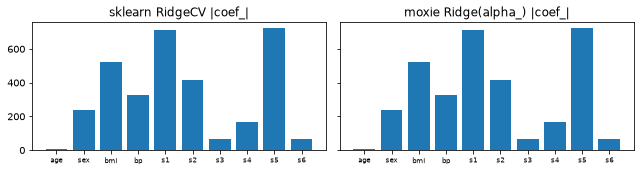

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
ridge coef_ vs RidgeCV,PASS,"(10,)","(10,)",1.23e-10,6.95e-13,"rtol=1e-08, atol=1e-08",,"same alpha; RidgeCV solves by eigendecomposition, Moxie Ridge by Cholesky (conditioning ~1e3)"
ridge coef_ vs Ridge(alpha_),PASS,"(10,)","(10,)",7.42e-11,4.41e-13,"rtol=1e-09, atol=1e-09",,both Cholesky on the normal equations; BLAS vs native reduction order
SelectFromModel support (example),PASS,"(10,)","(10,)",,,exact,0 mismatches,
SelectFromModel support (Ridge(alpha_)),PASS,"(10,)","(10,)",,,exact,0 mismatches,
SelectFromModel default threshold_ (mean),PASS,(),(),1.94e-11,6e-14,"rtol=1e-09, atol=0",,mean of |coef_| above
SelectFromModel threshold='1.5*median',PASS,"(10,)","(10,)",,,exact,0 mismatches,
SelectFromModel max_features=4,PASS,"(10,)","(10,)",,,exact,0 mismatches,
"SFS forward support (example, RidgeCV)",PASS,"(10,)","(10,)",,,exact,0 mismatches,
"SFS backward support (example, RidgeCV)",PASS,"(10,)","(10,)",,,exact,0 mismatches,
SFS forward support (Ridge(alpha_)),PASS,"(10,)","(10,)",,,exact,0 mismatches,


In [5]:
mx = nb.results["diabetes_selection"]
fig, axes = plt.subplots(1, 2, figsize=(9, 2.5), dpi=72, sharey=True)
axes[0].bar(height=importance, x=feature_names); axes[0].set_title("sklearn RidgeCV |coef_|")
axes[1].bar(height=np.abs(mx["coef"]), x=feature_names); axes[1].set_title("moxie Ridge(alpha_) |coef_|")
for ax in axes: ax.tick_params(axis="x", labelsize=7)
plt.tight_layout(); plt.show()
moxie_nb.side_by_side(
    sklearn=np.array([feature_names[sfm.get_support()], feature_names[sfs_forward.get_support()],
                      feature_names[sfs_backward.get_support()]], dtype=object),
    moxie=np.array([feature_names[mx["sfm_support"].astype(bool)], feature_names[mx["sfs_fwd"].astype(bool)],
                    feature_names[mx["sfs_bwd"].astype(bool)]], dtype=object))

nb.compare("ridge coef_ vs RidgeCV", ridge.coef_, mx["coef"], rtol=1e-8, atol=1e-8,
           reason="same alpha; RidgeCV solves by eigendecomposition, Moxie Ridge by Cholesky (conditioning ~1e3)")
nb.compare("ridge coef_ vs Ridge(alpha_)", ref["coef"], mx["coef"], rtol=1e-9, atol=1e-9,
           reason="both Cholesky on the normal equations; BLAS vs native reduction order")
nb.compare("SelectFromModel support (example)", sfm.get_support().astype(int), mx["sfm_support"], exact=True)
nb.compare("SelectFromModel support (Ridge(alpha_))", ref["sfm_fixed_support"].astype(int), mx["sfm_support"], exact=True)
nb.compare("SelectFromModel default threshold_ (mean)", ref["sfm_mean_threshold"], mx["sfm_mean_threshold"][0], rtol=1e-9,
           reason="mean of |coef_| above")
nb.compare("SelectFromModel threshold='1.5*median'", ref["sfm_median_support"].astype(int), mx["sfm_median_support"], exact=True)
nb.compare("SelectFromModel max_features=4", ref["sfm_max_features"].astype(int), mx["sfm_max_features"], exact=True)
nb.compare("SFS forward support (example, RidgeCV)", sfs_forward.get_support().astype(int), mx["sfs_fwd"], exact=True)
nb.compare("SFS backward support (example, RidgeCV)", sfs_backward.get_support().astype(int), mx["sfs_bwd"], exact=True)
nb.compare("SFS forward support (Ridge(alpha_))", ref["sfs_fwd_fixed"].astype(int), mx["sfs_fwd"], exact=True)
nb.compare("SFS backward support (Ridge(alpha_))", ref["sfs_bwd_fixed"].astype(int), mx["sfs_bwd"], exact=True)
nb.compare("SFS auto+tol support", ref["sfs_auto_support"].astype(int), mx["sfs_auto_support"], exact=True)
nb.compare("SFS auto+tol n_features_to_select_", ref["sfs_auto_count"], mx["sfs_auto_count"][0], exact=True)
nb.compare("RFE ranking_", ref["rfe_ranking"], mx["rfe_ranking"], exact=True)
nb.compare("RFE support_", ref["rfe_support"].astype(int), mx["rfe_support"], exact=True)
nb.compare("RFE predict", ref["rfe_predict"], mx["rfe_predict"], rtol=1e-9, atol=1e-9, reason="ridge refit on 3 columns; reduction order")
nb.compare("RFE score (R2)", ref["rfe_score"], mx["rfe_score"][0], rtol=1e-9, reason="as above")
nb.compare("RFECV n_features_", ref["rfecv_n_features"], mx["rfecv_n_features"][0], exact=True)
nb.compare("RFECV ranking_", ref["rfecv_ranking"], mx["rfecv_ranking"], exact=True)
nb.compare("RFECV mean_test_score", ref["rfecv_mean"], mx["rfecv_mean"], rtol=1e-8, atol=1e-10, reason="fold R2 of ridge fits; reduction order")
nb.compare("RFECV std_test_score", ref["rfecv_std"], mx["rfecv_std"], rtol=1e-6, atol=1e-10, reason="std of nearly equal fold scores amplifies their rounding")
nb.compare("RFECV split0_test_score", ref["rfecv_split0"], mx["rfecv_split0"], rtol=1e-8, atol=1e-10, reason="as mean")
nb.note("RidgeCV", "GAP", "no RidgeCV in moxie.linear_model; Ridge(alpha=RidgeCV.alpha_) used (owner: linear_model)")
nb.note("Breast-cancer part: SFS(LogisticRegression, scoring='roc_auc', tol, n_jobs=2) in a pipeline", "GAP",
        "no LogisticRegression (owner: linear_model, see #4 part 3); no scorer-name lookup; CV runs serially")
nb.report()
nb.assert_parity()